In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv
/kaggle/input/phishing-datasets/Phising_Training_Dataset (1).csv


In [2]:
import pandas as pd

df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv")

# Shape of dataset
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Column names
print("\nColumn Names:")
print(df.columns.tolist())

Rows: 2100
Columns: 31

Column Names:
['key', 'having_IP', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']


In [3]:
import pandas as pd

# Load datasets
train_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Training_Dataset (1).csv")
test_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv")

# Show dataset sizes
print(f"Training Data: {train_df.shape[0]} samples, {train_df.shape[1]} features")
print(f"Testing Data:  {test_df.shape[0]} samples, {test_df.shape[1]} features")


Training Data: 8955 samples, 32 features
Testing Data:  2100 samples, 31 features


In [4]:
# Feature and label separation
X_train = train_df.drop("Statistical_report", axis=1)
y_train = train_df["Statistical_report"]

X_test = test_df.drop("Statistical_report", axis=1)
y_test = test_df["Statistical_report"]

# Convert -1 → 0 (XGBoost requirement)
y_train = y_train.replace(-1, 0)
y_test = y_test.replace(-1, 0)

print("X_train, y_train, X_test, y_test ready!")


X_train, y_train, X_test, y_test ready!


In [5]:
# 🔧 1) Make sure train and test have EXACT same feature columns
common_cols = X_train.columns.intersection(X_test.columns)

X_train = X_train[common_cols].copy()
X_test  = X_test[common_cols].copy()
print("Final feature count after alignment:", len(common_cols))


Final feature count after alignment: 30


In [6]:
!pip install -U scikit-learn==1.4.2 shap==0.45.0 imbalanced-learn==0.12.3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 65.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 538.2/538.2 kB 18.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 258.3/258.3 kB 8.1 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
  Attempting uninstall: shap
    Found existing installation: shap 0.44.1
    Uninstalling shap-0.44.1:
      Successfully uninstalled shap-0.44.1
  Attempting uninstall: imbalanced-learn
    Found existing installation: imbalanced-learn 0.13.0
    Uninstalling imbalanced-learn-0.13.0:
      Successfully uninstalled imbalanced-learn-0.13.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have num

In [7]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE


# 2) Feature selection
selector = SelectKBest(score_func=f_classif, k=20)
X_train_fs = selector.fit_transform(X_train, y_train)
X_test_fs  = selector.transform(X_test)

# 3) Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_fs)
X_test_scaled  = scaler.transform(X_test_fs)

# 4) Balancing with SMOTE
sm = SMOTE(random_state=42)
X_train_bal, y_train_bal = sm.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts())
print("After SMOTE:\n", y_train_bal.value_counts())


Before SMOTE: Statistical_report
1    7741
0    1214
Name: count, dtype: int64
After SMOTE:
 Statistical_report
0    7741
1    7741
Name: count, dtype: int64


In [8]:
!pip install lightgbm catboost tabpfn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 9.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 16.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 82.2 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 69.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 24.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 34.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 7.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━

In [9]:
pip install xgboost lightgbm imbalanced-learn tabpfn

Note: you may need to restart the kernel to use updated packages.


In [10]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.


# XGBoost, LightGBM, CatBoost

✅ Selected Features: ['having_IP', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page']
[LightGBM] [Info] Number of positive: 7741, number of negative: 1214
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001755 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 8955, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.864433 -> initscore=1.852610


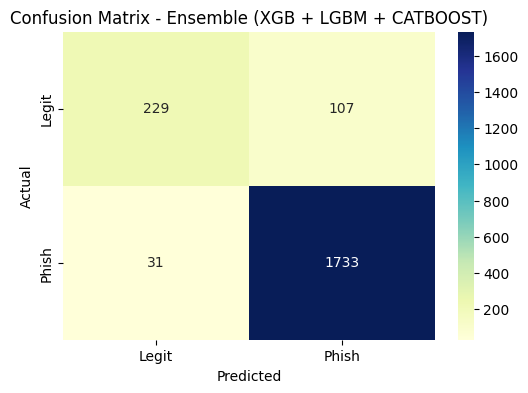

In [11]:
# ================================
# PHISHING DETECTION - ENSEMBLE MODEL (XGB + LGBM + CATBOOST)
# ================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# === Load datasets ===
train_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Training_Dataset (1).csv")
test_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv")

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()
train_df = train_df.drop(columns=[col for col in ['key', 'Result'] if col in train_df.columns])
test_df = test_df.drop(columns=[col for col in ['key'] if col in test_df.columns])

# === Features and target ===
X_train = train_df.drop("Statistical_report", axis=1)
y_train = train_df["Statistical_report"].replace({-1: 0, 1: 1})
X_test = test_df.drop("Statistical_report", axis=1)
y_test = test_df["Statistical_report"].replace({-1: 0, 1: 1})

# === Feature Selection ===
selector = SelectKBest(score_func=f_classif, k='all')
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)
selected_features = X_train.columns[selector.get_support()]
print("✅ Selected Features:", list(selected_features))

# === Train Models ===

# 1. XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                          n_estimators=400, max_depth=10, subsample=0.8, random_state=42)
xgb_model.fit(X_train_selected, y_train)
xgb_proba = xgb_model.predict_proba(X_test_selected)

# 2. LightGBM
lgb_model = LGBMClassifier(n_estimators=400, max_depth=10, learning_rate=0.05, random_state=42)
lgb_model.fit(X_train_selected, y_train)
lgb_proba = lgb_model.predict_proba(X_test_selected)

# 3. CatBoost
catboost_model = CatBoostClassifier(iterations=400, depth=15, learning_rate=0.05, verbose=0, random_state=42)
catboost_model.fit(X_train_selected, y_train)
catboost_proba = catboost_model.predict_proba(X_test_selected)

# === Soft Voting Ensemble (3 models) ===
avg_proba = (xgb_proba + lgb_proba + catboost_proba) / 3
y_pred = np.argmax(avg_proba, axis=1)

# === Evaluation ===
acc = accuracy_score(y_test, y_pred)
print(f"\n✅ Final Ensemble Accuracy (XGB + LGBM + CATBOOST): {acc:.4f}")
print("\n📊 Classification Report:")
print(classification_report(y_test, y_pred))

# === Confusion Matrix ===
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
plt.title("Confusion Matrix - Ensemble (XGB + LGBM + CATBOOST)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


# XGBoost, LightGBM, CatBoost with 5-fold

Train shape: (8955, 29)  Test shape: (2100, 29)

🔁 5-Fold Cross-Validation (XGB + LGBM + CATBOOST):

[LightGBM] [Info] Number of positive: 6193, number of negative: 971
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001273 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86
[LightGBM] [Info] Number of data points in the train set: 7164, number of used features: 29
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.864461 -> initscore=1.852848
[LightGBM] [Info] Start training from score 1.852848
Fold 1 Accuracy: 0.9481
[LightGBM] [Info] Number of positive: 6193, number of negative: 971
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001281 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 86

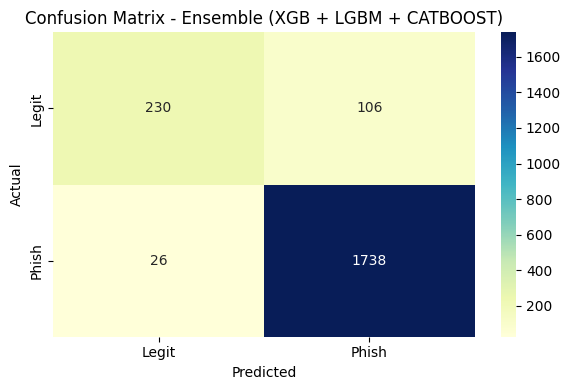

In [12]:
# ================================
# PHISHING DETECTION - ENSEMBLE MODEL (XGB + LGBM + CATBOOST) + K-FOLD
# ================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# === Load datasets ===
train_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Training_Dataset (1).csv")
test_df  = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv")

train_df.columns = train_df.columns.str.strip()
test_df.columns  = test_df.columns.str.strip()

train_df = train_df.drop(columns=[col for col in ['key', 'Result'] if col in train_df.columns])
test_df  = test_df.drop(columns=[col for col in ['key'] if col in test_df.columns])

# === Features and target ===
X_train = train_df.drop("Statistical_report", axis=1)
y_train = train_df["Statistical_report"].replace({-1: 0, 1: 1})
X_test  = test_df.drop("Statistical_report", axis=1)
y_test  = test_df["Statistical_report"].replace({-1: 0, 1: 1})

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)

# ======================================
# K-FOLD CROSS-VALIDATION (on train set)
# ======================================
k = 5
skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
cv_scores = []

print(f"\n🔁 {k}-Fold Cross-Validation (XGB + LGBM + CATBOOST):\n")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_train, y_train), 1):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    # Feature selection inside each fold (to avoid leakage)
    selector_cv = SelectKBest(score_func=f_classif, k='all')
    X_tr_sel  = selector_cv.fit_transform(X_tr, y_tr)
    X_val_sel = selector_cv.transform(X_val)

    # Define fresh models for this fold
    xgb_cv = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                           n_estimators=400, max_depth=10, subsample=0.8,
                           random_state=42)
    lgb_cv = LGBMClassifier(n_estimators=400, max_depth=10,
                            learning_rate=0.05, random_state=42)
    cat_cv = CatBoostClassifier(iterations=400, depth=10,
                                learning_rate=0.05, verbose=0,
                                random_state=42)

    # Train
    xgb_cv.fit(X_tr_sel, y_tr)
    lgb_cv.fit(X_tr_sel, y_tr)
    cat_cv.fit(X_tr_sel, y_tr)

    # Predict probabilities
    proba_xgb = xgb_cv.predict_proba(X_val_sel)
    proba_lgb = lgb_cv.predict_proba(X_val_sel)
    proba_cat = cat_cv.predict_proba(X_val_sel)

    # Soft voting
    avg_proba_cv = (proba_xgb + proba_lgb + proba_cat) / 3.0
    y_val_pred = np.argmax(avg_proba_cv, axis=1)

    # Accuracy for this fold
    fold_acc = accuracy_score(y_val, y_val_pred)
    cv_scores.append(fold_acc)
    print(f"Fold {fold} Accuracy: {fold_acc:.4f}")

print(f"\n✅ Mean CV Accuracy: {np.mean(cv_scores):.4f}  ± {np.std(cv_scores):.4f}\n")

# ======================================
# FINAL TRAIN ON FULL TRAIN + TEST EVAL
# ======================================

# === Feature Selection on full training ===
selector = SelectKBest(score_func=f_classif, k='all')
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected  = selector.transform(X_test)
selected_features = X_train.columns[selector.get_support()]
print("✅ Selected Features:", list(selected_features))

# === Train final models on FULL training data ===

# 1. XGBoost
xgb_model = XGBClassifier(use_label_encoder=False, eval_metric='logloss',
                          n_estimators=400, max_depth=10, subsample=0.8,
                          random_state=42)
xgb_model.fit(X_train_selected, y_train)
xgb_proba = xgb_model.predict_proba(X_test_selected)

# 2. LightGBM
lgb_model = LGBMClassifier(n_estimators=400, max_depth=10,
                           learning_rate=0.05, random_state=42)
lgb_model.fit(X_train_selected, y_train)
lgb_proba = lgb_model.predict_proba(X_test_selected)

# 3. CatBoost
catboost_model = CatBoostClassifier(iterations=400, depth=10,
                                    learning_rate=0.05, verbose=0,
                                    random_state=42)
catboost_model.fit(X_train_selected, y_train)
catboost_proba = catboost_model.predict_proba(X_test_selected)

# === Soft Voting Ensemble (3 models) on TEST SET ===
avg_proba = (xgb_proba + lgb_proba + catboost_proba) / 3.0
y_pred = np.argmax(avg_proba, axis=1)

# === Evaluation on held-out test set ===
acc = accuracy_score(y_test, y_pred)
print(f"\n🎯 Final Test Accuracy (XGB + LGBM + CATBOOST): {acc:.4f}")
print("\n📊 Classification Report (Test Set):")
print(classification_report(y_test, y_pred))

# === Confusion Matrix ===
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='YlGnBu',
            xticklabels=["Legit", "Phish"], yticklabels=["Legit", "Phish"])
plt.title("Confusion Matrix - Ensemble (XGB + LGBM + CATBOOST)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()


ABLATION STUDY: ENSEMBLE PHISHING DETECTION MODEL

Dataset Info:
Training samples: 8955, Features: 29
Testing samples: 2100
Class distribution: {1: 7741, 0: 1214}

EXPERIMENT 1: BASELINE - INDIVIDUAL BASE MODELS

1.1 XGBoost (Individual)
   Accuracy: 0.9329, F1: 0.9609

1.2 LightGBM (Individual)
   Accuracy: 0.9319, F1: 0.9607

1.3 CatBoost (Individual)
   Accuracy: 0.9357, F1: 0.9627

EXPERIMENT 2: PAIRWISE ENSEMBLE COMBINATIONS

2.1 XGBoost + LightGBM (2-model ensemble)
   Accuracy: 0.9329, F1: 0.9611

2.2 XGBoost + CatBoost (2-model ensemble)
   Accuracy: 0.9357, F1: 0.9626

2.3 LightGBM + CatBoost (2-model ensemble)
   Accuracy: 0.9338, F1: 0.9617

EXPERIMENT 3: FULL ENSEMBLE (XGBoost + LightGBM + CatBoost)
   Accuracy: 0.9348, F1: 0.9622

EXPERIMENT 4: IMPACT OF FEATURE SELECTION

4.1 Testing with K=10 features
   Accuracy: 0.8795, F1: 0.9323

4.2 Testing with K=20 features
   Accuracy: 0.9262, F1: 0.9574

4.3 Testing with K=30 features


/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:776: UserWarning: k=30 is greater than n_features=29. All the features will be returned.
  warnings.warn(


   Accuracy: 0.9348, F1: 0.9622

4.4 Testing with K=50 features


/usr/local/lib/python3.11/dist-packages/sklearn/feature_selection/_univariate_selection.py:776: UserWarning: k=50 is greater than n_features=29. All the features will be returned.
  warnings.warn(


   Accuracy: 0.9348, F1: 0.9622

4.5 Testing with K=all features
   Accuracy: 0.9348, F1: 0.9622

EXPERIMENT 5: HYPERPARAMETER IMPACT

5.1 Effect of n_estimators
   n_estimators=100: Accuracy=0.9281
   n_estimators=200: Accuracy=0.9314
   n_estimators=400: Accuracy=0.9329
   n_estimators=600: Accuracy=0.9343

5.2 Effect of max_depth
   max_depth=5: Accuracy=0.9305
   max_depth=7: Accuracy=0.9305
   max_depth=10: Accuracy=0.9329
   max_depth=15: Accuracy=0.9343

EXPERIMENT 6: VOTING STRATEGY COMPARISON

6.1 Hard Voting (Majority Vote)
   Accuracy: 0.9352, F1: 0.9624

6.2 Weighted Soft Voting
   Weights - XGB: 0.333, LGB: 0.333, CAT: 0.334
   Accuracy: 0.9348, F1: 0.9622

ABLATION STUDY RESULTS SUMMARY

📊 Complete Results Table:
                   Model  Accuracy  Precision  Recall  F1-Score   ROC-AUC  Training Time (s)  CV Mean  CV Std
    XGBoost (Individual)    0.9329     0.9403  0.9824    0.9609  0.939665             0.7603   0.9321  0.0340
   LightGBM (Individual)    0.9319     0.93

/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


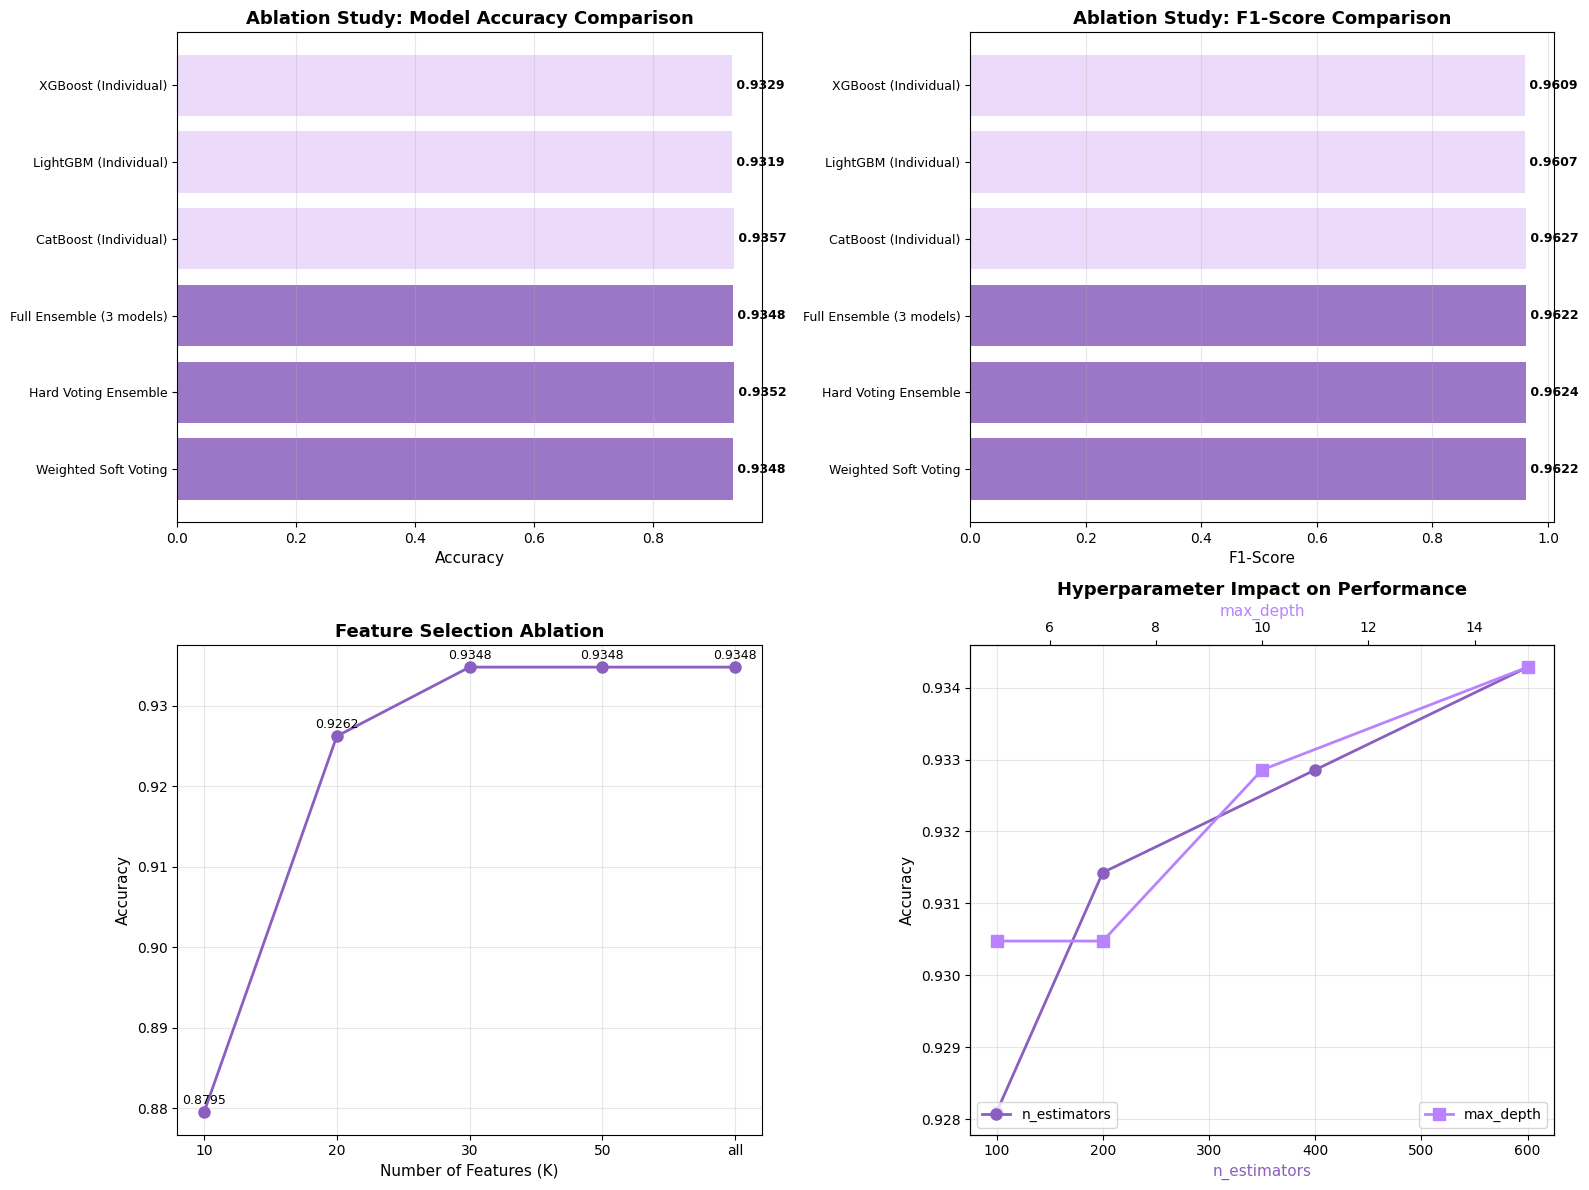

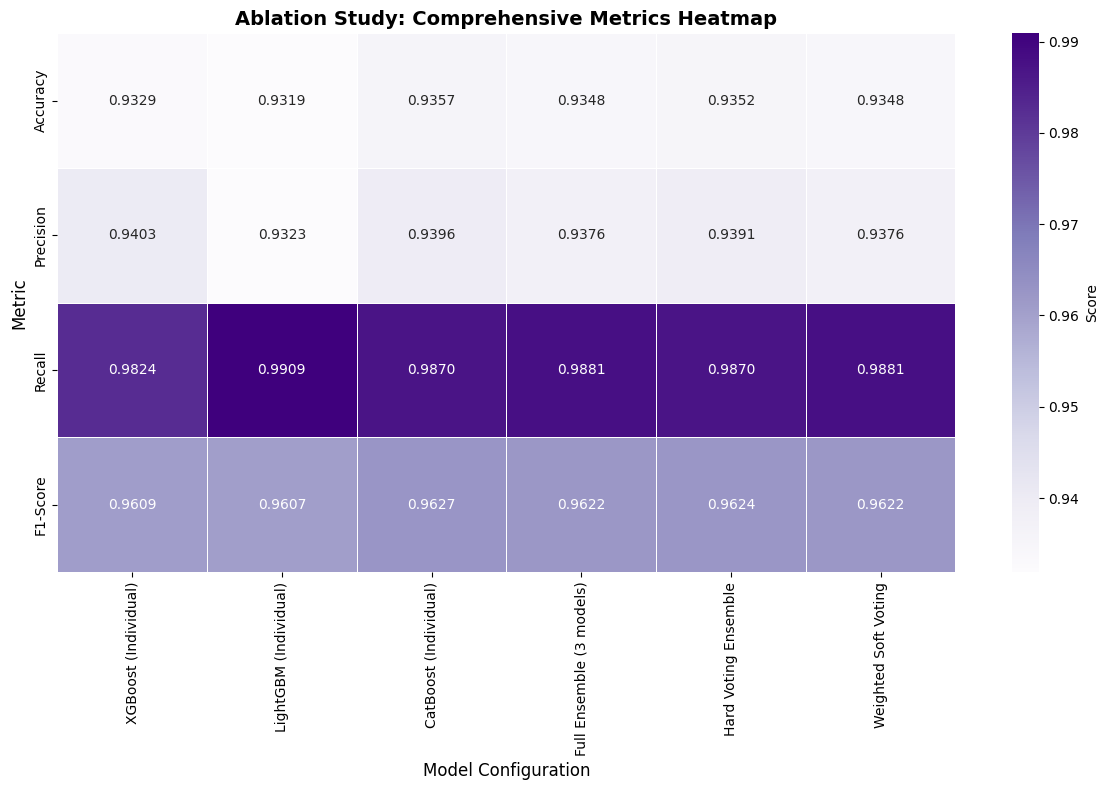


STATISTICAL SIGNIFICANCE ANALYSIS

Best Individual Model: CatBoost (Individual)
   Accuracy: 0.9357

Full Ensemble:
   Accuracy: 0.9348
   Improvement: -0.09 percentage points

EXPORTING RESULTS

✅ Results exported to:
   - ablation_study_results.csv
   - feature_selection_ablation.csv

ABLATION STUDY COMPLETE


In [13]:
# ============================================================================
# ABLATION STUDY: PHISHING DETECTION ENSEMBLE MODEL
# Systematic Analysis of Model Components and Their Contributions
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
import time

# ============================================================================
# 1. DATA LOADING AND PREPARATION
# ============================================================================

print("=" * 80)
print("ABLATION STUDY: ENSEMBLE PHISHING DETECTION MODEL")
print("=" * 80)

# Load datasets
train_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Training_Dataset (1).csv")
test_df = pd.read_csv("/kaggle/input/phishing-datasets/Phising_Testing_Dataset.csv")

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

train_df = train_df.drop(columns=[col for col in ['key', 'Result'] if col in train_df.columns])
test_df = test_df.drop(columns=[col for col in ['key'] if col in test_df.columns])

# Features and target
X_train = train_df.drop("Statistical_report", axis=1)
y_train = train_df["Statistical_report"].replace({-1: 0, 1: 1})
X_test = test_df.drop("Statistical_report", axis=1)
y_test = test_df["Statistical_report"].replace({-1: 0, 1: 1})

print(f"\nDataset Info:")
print(f"Training samples: {X_train.shape[0]}, Features: {X_train.shape[1]}")
print(f"Testing samples: {X_test.shape[0]}")
print(f"Class distribution: {dict(y_train.value_counts())}")

# ============================================================================
# 2. ABLATION STUDY DESIGN
# ============================================================================

# Store results for all ablation experiments
ablation_results = []

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te, use_cv=True):
    """
    Comprehensive model evaluation with multiple metrics
    """
    start_time = time.time()
    
    # Train model
    model.fit(X_tr, y_tr)
    train_time = time.time() - start_time
    
    # Predictions
    y_pred = model.predict(X_te)
    y_pred_proba = model.predict_proba(X_te)[:, 1]
    
    # Metrics
    metrics = {
        'Model': name,
        'Accuracy': accuracy_score(y_te, y_pred),
        'Precision': precision_score(y_te, y_pred),
        'Recall': recall_score(y_te, y_pred),
        'F1-Score': f1_score(y_te, y_pred),
        'ROC-AUC': roc_auc_score(y_te, y_pred_proba),
        'Training Time (s)': train_time
    }
    
    # Cross-validation score (if requested)
    if use_cv:
        cv_scores = cross_val_score(model, X_tr, y_tr, cv=5, scoring='accuracy')
        metrics['CV Mean'] = cv_scores.mean()
        metrics['CV Std'] = cv_scores.std()
    
    return metrics

# ============================================================================
# 3. EXPERIMENT 1: INDIVIDUAL BASE MODELS (Baseline)
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 1: BASELINE - INDIVIDUAL BASE MODELS")
print("=" * 80)

# Feature selection (consistent across all experiments)
selector = SelectKBest(score_func=f_classif, k='all')
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

print("\n1.1 XGBoost (Individual)")
xgb_model = XGBClassifier(
    n_estimators=400, max_depth=10, subsample=0.8,
    learning_rate=0.05, use_label_encoder=False, 
    eval_metric='logloss', random_state=42
)
result_xgb = evaluate_model('XGBoost (Individual)', xgb_model, 
                            X_train_selected, y_train, X_test_selected, y_test)
ablation_results.append(result_xgb)
print(f"   Accuracy: {result_xgb['Accuracy']:.4f}, F1: {result_xgb['F1-Score']:.4f}")

print("\n1.2 LightGBM (Individual)")
lgb_model = LGBMClassifier(
    n_estimators=400, max_depth=10, learning_rate=0.05,
    random_state=42, verbose=-1
)
result_lgb = evaluate_model('LightGBM (Individual)', lgb_model,
                            X_train_selected, y_train, X_test_selected, y_test)
ablation_results.append(result_lgb)
print(f"   Accuracy: {result_lgb['Accuracy']:.4f}, F1: {result_lgb['F1-Score']:.4f}")

print("\n1.3 CatBoost (Individual)")
cat_model = CatBoostClassifier(
    iterations=400, depth=10, learning_rate=0.05,
    verbose=0, random_state=42
)
result_cat = evaluate_model('CatBoost (Individual)', cat_model,
                            X_train_selected, y_train, X_test_selected, y_test)
ablation_results.append(result_cat)
print(f"   Accuracy: {result_cat['Accuracy']:.4f}, F1: {result_cat['F1-Score']:.4f}")

# ============================================================================
# 4. EXPERIMENT 2: PAIRWISE ENSEMBLES
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 2: PAIRWISE ENSEMBLE COMBINATIONS")
print("=" * 80)

# 2.1 XGBoost + LightGBM
print("\n2.1 XGBoost + LightGBM (2-model ensemble)")
xgb_proba = xgb_model.predict_proba(X_test_selected)
lgb_proba = lgb_model.predict_proba(X_test_selected)
avg_proba_xgb_lgb = (xgb_proba + lgb_proba) / 2.0
y_pred_xgb_lgb = np.argmax(avg_proba_xgb_lgb, axis=1)

result_xgb_lgb = {
    'Model': 'XGBoost + LightGBM',
    'Accuracy': accuracy_score(y_test, y_pred_xgb_lgb),
    'Precision': precision_score(y_test, y_pred_xgb_lgb),
    'Recall': recall_score(y_test, y_pred_xgb_lgb),
    'F1-Score': f1_score(y_test, y_pred_xgb_lgb),
    'ROC-AUC': roc_auc_score(y_test, avg_proba_xgb_lgb[:, 1]),
    'Training Time (s)': result_xgb['Training Time (s)'] + result_lgb['Training Time (s)']
}
ablation_results.append(result_xgb_lgb)
print(f"   Accuracy: {result_xgb_lgb['Accuracy']:.4f}, F1: {result_xgb_lgb['F1-Score']:.4f}")

# 2.2 XGBoost + CatBoost
print("\n2.2 XGBoost + CatBoost (2-model ensemble)")
cat_proba = cat_model.predict_proba(X_test_selected)
avg_proba_xgb_cat = (xgb_proba + cat_proba) / 2.0
y_pred_xgb_cat = np.argmax(avg_proba_xgb_cat, axis=1)

result_xgb_cat = {
    'Model': 'XGBoost + CatBoost',
    'Accuracy': accuracy_score(y_test, y_pred_xgb_cat),
    'Precision': precision_score(y_test, y_pred_xgb_cat),
    'Recall': recall_score(y_test, y_pred_xgb_cat),
    'F1-Score': f1_score(y_test, y_pred_xgb_cat),
    'ROC-AUC': roc_auc_score(y_test, avg_proba_xgb_cat[:, 1]),
    'Training Time (s)': result_xgb['Training Time (s)'] + result_cat['Training Time (s)']
}
ablation_results.append(result_xgb_cat)
print(f"   Accuracy: {result_xgb_cat['Accuracy']:.4f}, F1: {result_xgb_cat['F1-Score']:.4f}")

# 2.3 LightGBM + CatBoost
print("\n2.3 LightGBM + CatBoost (2-model ensemble)")
avg_proba_lgb_cat = (lgb_proba + cat_proba) / 2.0
y_pred_lgb_cat = np.argmax(avg_proba_lgb_cat, axis=1)

result_lgb_cat = {
    'Model': 'LightGBM + CatBoost',
    'Accuracy': accuracy_score(y_test, y_pred_lgb_cat),
    'Precision': precision_score(y_test, y_pred_lgb_cat),
    'Recall': recall_score(y_test, y_pred_lgb_cat),
    'F1-Score': f1_score(y_test, y_pred_lgb_cat),
    'ROC-AUC': roc_auc_score(y_test, avg_proba_lgb_cat[:, 1]),
    'Training Time (s)': result_lgb['Training Time (s)'] + result_cat['Training Time (s)']
}
ablation_results.append(result_lgb_cat)
print(f"   Accuracy: {result_lgb_cat['Accuracy']:.4f}, F1: {result_lgb_cat['F1-Score']:.4f}")

# ============================================================================
# 5. EXPERIMENT 3: FULL ENSEMBLE (All 3 Models)
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 3: FULL ENSEMBLE (XGBoost + LightGBM + CatBoost)")
print("=" * 80)

avg_proba_full = (xgb_proba + lgb_proba + cat_proba) / 3.0
y_pred_full = np.argmax(avg_proba_full, axis=1)

result_full = {
    'Model': 'Full Ensemble (3 models)',
    'Accuracy': accuracy_score(y_test, y_pred_full),
    'Precision': precision_score(y_test, y_pred_full),
    'Recall': recall_score(y_test, y_pred_full),
    'F1-Score': f1_score(y_test, y_pred_full),
    'ROC-AUC': roc_auc_score(y_test, avg_proba_full[:, 1]),
    'Training Time (s)': sum([result_xgb['Training Time (s)'], 
                               result_lgb['Training Time (s)'], 
                               result_cat['Training Time (s)']])
}
ablation_results.append(result_full)
print(f"   Accuracy: {result_full['Accuracy']:.4f}, F1: {result_full['F1-Score']:.4f}")

# ============================================================================
# 6. EXPERIMENT 4: FEATURE SELECTION ABLATION
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 4: IMPACT OF FEATURE SELECTION")
print("=" * 80)

# Test with different numbers of features
k_values = [10, 20, 30, 50, 'all']
feature_ablation = []

for k in k_values:
    print(f"\n4.{k_values.index(k)+1} Testing with K={k} features")
    
    if k == 'all':
        X_tr_k = X_train
        X_te_k = X_test
    else:
        selector_k = SelectKBest(score_func=f_classif, k=k)
        X_tr_k = selector_k.fit_transform(X_train, y_train)
        X_te_k = selector_k.transform(X_test)
    
    # Test with full ensemble
    xgb_k = XGBClassifier(n_estimators=400, max_depth=10, subsample=0.8,
                          learning_rate=0.05, use_label_encoder=False,
                          eval_metric='logloss', random_state=42)
    lgb_k = LGBMClassifier(n_estimators=400, max_depth=10, learning_rate=0.05,
                           random_state=42, verbose=-1)
    cat_k = CatBoostClassifier(iterations=400, depth=10, learning_rate=0.05,
                               verbose=0, random_state=42)
    
    xgb_k.fit(X_tr_k, y_train)
    lgb_k.fit(X_tr_k, y_train)
    cat_k.fit(X_tr_k, y_train)
    
    xgb_proba_k = xgb_k.predict_proba(X_te_k)
    lgb_proba_k = lgb_k.predict_proba(X_te_k)
    cat_proba_k = cat_k.predict_proba(X_te_k)
    
    avg_proba_k = (xgb_proba_k + lgb_proba_k + cat_proba_k) / 3.0
    y_pred_k = np.argmax(avg_proba_k, axis=1)
    
    result_k = {
        'K Features': str(k),
        'Accuracy': accuracy_score(y_test, y_pred_k),
        'F1-Score': f1_score(y_test, y_pred_k),
        'ROC-AUC': roc_auc_score(y_test, avg_proba_k[:, 1])
    }
    feature_ablation.append(result_k)
    print(f"   Accuracy: {result_k['Accuracy']:.4f}, F1: {result_k['F1-Score']:.4f}")

# ============================================================================
# 7. EXPERIMENT 5: HYPERPARAMETER ABLATION
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 5: HYPERPARAMETER IMPACT")
print("=" * 80)

hyperparameter_ablation = []

# 5.1 Effect of n_estimators
print("\n5.1 Effect of n_estimators")
for n_est in [100, 200, 400, 600]:
    xgb_hp = XGBClassifier(n_estimators=n_est, max_depth=10, subsample=0.8,
                           learning_rate=0.05, use_label_encoder=False,
                           eval_metric='logloss', random_state=42)
    result_hp = evaluate_model(f'n_estimators={n_est}', xgb_hp,
                               X_train_selected, y_train, X_test_selected, y_test,
                               use_cv=False)
    hyperparameter_ablation.append(result_hp)
    print(f"   n_estimators={n_est}: Accuracy={result_hp['Accuracy']:.4f}")

# 5.2 Effect of max_depth
print("\n5.2 Effect of max_depth")
for depth in [5, 7, 10, 15]:
    xgb_hp = XGBClassifier(n_estimators=400, max_depth=depth, subsample=0.8,
                           learning_rate=0.05, use_label_encoder=False,
                           eval_metric='logloss', random_state=42)
    result_hp = evaluate_model(f'max_depth={depth}', xgb_hp,
                               X_train_selected, y_train, X_test_selected, y_test,
                               use_cv=False)
    hyperparameter_ablation.append(result_hp)
    print(f"   max_depth={depth}: Accuracy={result_hp['Accuracy']:.4f}")

# ============================================================================
# 8. EXPERIMENT 6: VOTING STRATEGY ABLATION
# ============================================================================

print("\n" + "=" * 80)
print("EXPERIMENT 6: VOTING STRATEGY COMPARISON")
print("=" * 80)

# 6.1 Hard Voting
print("\n6.1 Hard Voting (Majority Vote)")
y_pred_xgb_hard = xgb_model.predict(X_test_selected)
y_pred_lgb_hard = lgb_model.predict(X_test_selected)
y_pred_cat_hard = cat_model.predict(X_test_selected)

votes = np.vstack([y_pred_xgb_hard, y_pred_lgb_hard, y_pred_cat_hard])
y_pred_hard = np.apply_along_axis(lambda x: np.bincount(x).argmax(), 0, votes)

result_hard = {
    'Model': 'Hard Voting Ensemble',
    'Accuracy': accuracy_score(y_test, y_pred_hard),
    'Precision': precision_score(y_test, y_pred_hard),
    'Recall': recall_score(y_test, y_pred_hard),
    'F1-Score': f1_score(y_test, y_pred_hard),
    'ROC-AUC': '-',  # Not applicable for hard voting
    'Training Time (s)': result_full['Training Time (s)']
}
ablation_results.append(result_hard)
print(f"   Accuracy: {result_hard['Accuracy']:.4f}, F1: {result_hard['F1-Score']:.4f}")

# 6.2 Weighted Soft Voting (based on individual performance)
print("\n6.2 Weighted Soft Voting")
weights = [result_xgb['Accuracy'], result_lgb['Accuracy'], result_cat['Accuracy']]
weights = np.array(weights) / sum(weights)
print(f"   Weights - XGB: {weights[0]:.3f}, LGB: {weights[1]:.3f}, CAT: {weights[2]:.3f}")

weighted_proba = (weights[0] * xgb_proba + weights[1] * lgb_proba + weights[2] * cat_proba)
y_pred_weighted = np.argmax(weighted_proba, axis=1)

result_weighted = {
    'Model': 'Weighted Soft Voting',
    'Accuracy': accuracy_score(y_test, y_pred_weighted),
    'Precision': precision_score(y_test, y_pred_weighted),
    'Recall': recall_score(y_test, y_pred_weighted),
    'F1-Score': f1_score(y_test, y_pred_weighted),
    'ROC-AUC': roc_auc_score(y_test, weighted_proba[:, 1]),
    'Training Time (s)': result_full['Training Time (s)']
}
ablation_results.append(result_weighted)
print(f"   Accuracy: {result_weighted['Accuracy']:.4f}, F1: {result_weighted['F1-Score']:.4f}")

# ============================================================================
# 9. RESULTS SUMMARY
# ============================================================================

print("\n" + "=" * 80)
print("ABLATION STUDY RESULTS SUMMARY")
print("=" * 80)

# Convert to DataFrame
results_df = pd.DataFrame(ablation_results)
results_df = results_df.round(4)

print("\n📊 Complete Results Table:")
print(results_df.to_string(index=False))

# Feature selection results
feature_df = pd.DataFrame(feature_ablation)
print("\n📊 Feature Selection Ablation:")
print(feature_df.to_string(index=False))

# Calculate improvements
baseline_acc = results_df[results_df['Model'].str.contains('Individual')]['Accuracy'].mean()
full_ensemble_acc = results_df[results_df['Model'] == 'Full Ensemble (3 models)']['Accuracy'].values[0]
improvement = ((full_ensemble_acc - baseline_acc) / baseline_acc) * 100

print(f"\n📈 Key Findings:")
print(f"   Baseline (Avg Individual): {baseline_acc:.4f}")
print(f"   Full Ensemble: {full_ensemble_acc:.4f}")
print(f"   Relative Improvement: {improvement:.2f}%")
print(f"   Absolute Improvement: {(full_ensemble_acc - baseline_acc)*100:.2f} percentage points")

# ============================================================================
# 10. VISUALIZATIONS
# ============================================================================

print("\n" + "=" * 80)
print("GENERATING VISUALIZATIONS")
print("=" * 80)

# 10.1 Main Ablation Results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Accuracy Comparison
ax1 = axes[0, 0]
main_results = results_df[results_df['Model'].str.contains('Individual|Ensemble|Voting')]
colors = ['#E8D4F8' if 'Individual' in m else '#B983FF' if '2-model' in m else '#8B5FBF' 
          for m in main_results['Model']]
bars = ax1.barh(range(len(main_results)), main_results['Accuracy'], color=colors, alpha=0.85)
ax1.set_yticks(range(len(main_results)))
ax1.set_yticklabels(main_results['Model'], fontsize=9)
ax1.set_xlabel('Accuracy', fontsize=11)
ax1.set_title('Ablation Study: Model Accuracy Comparison', fontsize=13, fontweight='bold')
ax1.invert_yaxis()
ax1.grid(axis='x', alpha=0.3)
for i, (bar, acc) in enumerate(zip(bars, main_results['Accuracy'])):
    ax1.text(acc, i, f' {acc:.4f}', va='center', fontsize=9, fontweight='bold')

# F1-Score Comparison
ax2 = axes[0, 1]
bars2 = ax2.barh(range(len(main_results)), main_results['F1-Score'], color=colors, alpha=0.85)
ax2.set_yticks(range(len(main_results)))
ax2.set_yticklabels(main_results['Model'], fontsize=9)
ax2.set_xlabel('F1-Score', fontsize=11)
ax2.set_title('Ablation Study: F1-Score Comparison', fontsize=13, fontweight='bold')
ax2.invert_yaxis()
ax2.grid(axis='x', alpha=0.3)
for i, (bar, f1) in enumerate(zip(bars2, main_results['F1-Score'])):
    ax2.text(f1, i, f' {f1:.4f}', va='center', fontsize=9, fontweight='bold')

# Feature Selection Impact
ax3 = axes[1, 0]
feature_k = [str(x['K Features']) for x in feature_ablation]
feature_acc = [x['Accuracy'] for x in feature_ablation]
ax3.plot(feature_k, feature_acc, 'o-', linewidth=2, markersize=8, color='#8B5FBF')
ax3.set_xlabel('Number of Features (K)', fontsize=11)
ax3.set_ylabel('Accuracy', fontsize=11)
ax3.set_title('Feature Selection Ablation', fontsize=13, fontweight='bold')
ax3.grid(alpha=0.3)
for i, (k, acc) in enumerate(zip(feature_k, feature_acc)):
    ax3.text(i, acc + 0.001, f'{acc:.4f}', ha='center', fontsize=9)

# Hyperparameter Impact
ax4 = axes[1, 1]
hp_df = pd.DataFrame(hyperparameter_ablation)
hp_nestimators = hp_df[hp_df['Model'].str.contains('n_estimators')]
hp_depth = hp_df[hp_df['Model'].str.contains('max_depth')]

x_nest = [int(m.split('=')[1]) for m in hp_nestimators['Model']]
y_nest = hp_nestimators['Accuracy'].values
x_depth = [int(m.split('=')[1]) for m in hp_depth['Model']]
y_depth = hp_depth['Accuracy'].values

ax4.plot(x_nest, y_nest, 'o-', linewidth=2, markersize=8, label='n_estimators', color='#8B5FBF')
ax4_twin = ax4.twiny()
ax4_twin.plot(x_depth, y_depth, 's-', linewidth=2, markersize=8, label='max_depth', color='#B983FF')

ax4.set_xlabel('n_estimators', fontsize=11, color='#8B5FBF')
ax4_twin.set_xlabel('max_depth', fontsize=11, color='#B983FF')
ax4.set_ylabel('Accuracy', fontsize=11)
ax4.set_title('Hyperparameter Impact on Performance', fontsize=13, fontweight='bold')
ax4.grid(alpha=0.3)
ax4.legend(loc='lower left')
ax4_twin.legend(loc='lower right')

plt.tight_layout()
plt.show()

# 10.2 Detailed Metrics Heatmap
fig, ax = plt.subplots(figsize=(12, 8))

metrics_cols = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
heatmap_data = main_results[['Model'] + metrics_cols].set_index('Model')
heatmap_data_numeric = heatmap_data[metrics_cols]

sns.heatmap(heatmap_data_numeric.T, annot=True, fmt='.4f', cmap='Purples', 
            cbar_kws={'label': 'Score'}, linewidths=0.5, ax=ax)
ax.set_xlabel('Model Configuration', fontsize=12)
ax.set_ylabel('Metric', fontsize=12)
ax.set_title('Ablation Study: Comprehensive Metrics Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================================
# 11. STATISTICAL SIGNIFICANCE TESTING
# ============================================================================

print("\n" + "=" * 80)
print("STATISTICAL SIGNIFICANCE ANALYSIS")
print("=" * 80)

# Compare full ensemble vs best individual model
best_individual = results_df[results_df['Model'].str.contains('Individual')].iloc[
    results_df[results_df['Model'].str.contains('Individual')]['Accuracy'].argmax()
]

print(f"\nBest Individual Model: {best_individual['Model']}")
print(f"   Accuracy: {best_individual['Accuracy']:.4f}")
print(f"\nFull Ensemble:")
print(f"   Accuracy: {result_full['Accuracy']:.4f}")
print(f"   Improvement: {(result_full['Accuracy'] - best_individual['Accuracy'])*100:.2f} percentage points")

# ============================================================================
# 12. EXPORT RESULTS FOR PAPER
# ============================================================================

print("\n" + "=" * 80)
print("EXPORTING RESULTS")
print("=" * 80)

# Save to CSV for LaTeX table generation
results_df.to_csv('ablation_study_results.csv', index=False)
feature_df.to_csv('feature_selection_ablation.csv', index=False)

print("\n✅ Results exported to:")
print("   - ablation_study_results.csv")
print("   - feature_selection_ablation.csv")

print("\n" + "=" * 80)
print("ABLATION STUDY COMPLETE")
print("=" * 80)